In [ ]:
# [셀 G0] 파일 모양 확인: 올린 파일마다 열 이름과 앞 3줄을 보여 줌
import os, pandas as pd
from google.colab import files
def peek(f):
    if f.lower().endswith((".xlsx", ".xls")): d = pd.read_excel(f, header=None, nrows=8)
    else:
        for enc in ["utf-8-sig", "cp949"]:
            try: d = pd.read_csv(f, encoding=enc, header=None, nrows=8, dtype=str); break
            except UnicodeDecodeError: pass
    n_rows = len(pd.read_excel(f, header=None)) if f.lower().endswith((".xlsx", ".xls")) else sum(1 for _ in open(f, "rb"))
    first = d.iloc[0].astype(str).tolist()
    print(f"\n===== {f} / 대략 {n_rows}줄 / {len(first)}열")
    print("첫 줄:", first[:10], "..." if len(first) > 15 else "", first[-5:] if len(first) > 15 else "")
    print(d.iloc[1:4, :min(len(first), 8)].to_string(index=False, header=False))
for f in files.upload(): peek(f)

Saving 2026년 6월 인천광역시_연령별인구현황_월간.xlsx to 2026년 6월 인천광역시_연령별인구현황_월간.xlsx
Saving P6_인천광역시_2016_2021_고령인구_비교.xlsx to P6_인천광역시_2016_2021_고령인구_비교.xlsx
Saving 시도별_간이생명표_5세별__20261012181211.csv to 시도별_간이생명표_5세별__20261012181211.csv


/usr/local/lib/python3.13/dist-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")
/usr/local/lib/python3.13/dist-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")



===== 2026년 6월 인천광역시_연령별인구현황_월간.xlsx / 대략 15줄 / 311열
첫 줄: ['※ 매월 말일자 통계 현황', 'nan', 'nan', 'nan', 'nan', 'nan', 'nan', 'nan', 'nan', 'nan'] ... ['nan', 'nan', 'nan', 'nan', 'nan']
   NaN  NaN 2026년06월     NaN NaN NaN NaN NaN
   NaN  NaN        계     NaN NaN NaN NaN NaN
행정기관코드 행정기관    총 인구수 연령구간인구수  0세  1세  2세  3세

===== P6_인천광역시_2016_2021_고령인구_비교.xlsx / 대략 168줄 / 6열
첫 줄: ['구', '통합_동', 'eld_2016', 'eld_2021', 'pop_2016', 'pop_2021']  
강화군 강화읍 4677 5653 22824 22697
강화군 교동면 1221 1305  2980  2877
강화군 길상면 1705 2219  6663  7037

===== 시도별_간이생명표_5세별__20261012181211.csv / 대략 11줄 / 3열
첫 줄: ['시도별', '연령별', '2023']  
  시도별 연령별 정지인구(전체) (명)
인천광역시  60       464096
인천광역시  65       449051


In [ ]:
# [셀 E0] P6 파일 → dong_history.csv: 2026 행정동(156개) 기준으로 맞추기
import os, re, numpy as np, pandas as pd
from google.colab import files
def find(word):                                                          # 이름에 word가 든 파일 중 가장 최근 것
    fs = [f for f in os.listdir() if word in f and not f.startswith(".")]
    return max(fs, key=os.path.getmtime) if fs else None
if not os.path.exists("dong_master.csv") or find("P6") is None:
    print("올릴 파일: dong_master.csv(D5 최신본), P6 파일")
    for f in files.upload():
        if f.startswith("dong_master") and f != "dong_master.csv": os.rename(f, "dong_master.csv")
dm = pd.read_csv("dong_master.csv", dtype={"adm_cd": str})
GU = {"23010": "중구", "23020": "동구", "23030": "미추홀구", "23090": "미추홀구", "23040": "연수구", "23050": "남동구",
      "23060": "부평구", "23070": "계양구", "23080": "서구", "23510": "강화군", "23520": "옹진군"}
dm["gu"] = dm["adm_cd"].str[:5].map(GU)
if "sgg_nm" in dm: dm["gu"] = dm["gu"].fillna(dm["sgg_nm"].astype(str).str.split().str[-1])
print("구를 못 정한 동:", dm.loc[dm["gu"].isna(), "adm_nm"].tolist())
norm = lambda s: re.sub(r"제(?=\d)", "", re.sub(r"[\s·.,ㆍ]", "", str(s)))     # 1.4동 / 1,4동 / 1·4동 / 제1동 표기 차이 없애기
KEY = {(g, norm(n)): cd for cd, g, n in zip(dm["adm_cd"], dm["gu"], dm["adm_nm"])}
VC = ["eld_2016", "eld_2021", "pop_2016", "pop_2021"]
h = pd.read_excel(find("P6")).dropna(subset=["통합_동"])
h[VC] = h[VC].replace(0, np.nan)                                         # 0은 그 해 값이 없다는 뜻으로 봄
h["구"] = h["구"].astype(str).str.split().str[-1].replace({"남구": "미추홀구"})          # 2018년 남구 → 미추홀구
h = h[~h["통합_동"].astype(str).str.contains("소계|합계|^계$|기타")]                    # 구 합계·구 단위 기타 줄 빼기
h["k"] = h["통합_동"].map(norm)
dup = h[h.duplicated(["구", "k"], keep=False)]
if len(dup): print("표기만 다른 중복 줄 (빈 칸을 서로 채워 한 줄로 합침):\n" + dup[["구", "통합_동"] + VC].to_string(index=False))
h = h.groupby(["구", "k"], as_index=False).agg({"통합_동": "first", **{c: "first" for c in VC}})
ALIAS = {"강화군|서도면볼음출장소": "서도면", "옹진군|대청면소청출장소": "대청면", "옹진군|북도면장봉출장소": "북도면",
         "옹진군|자월면이작출장소": "자월면", "중구|용유출장무의지소": "용유동",                  # 출장소 인구는 본 면·동에 더함
         "중구|북성동": "개항동", "중구|송월동": "개항동",                                    # 북성동 + 송월동 → 개항동
         "서구|검단5동": "오류왕길동",                                                       # 2018년 검단5동 → 오류왕길동
         "중구|영종동": "영종 묶음", "중구|영종1동": "영종 묶음", "중구|영종출장중산지소": "영종 묶음"}
h["통합_동"] = [ALIAS.get(f"{g}|{n}", n) for g, n in zip(h["구"], h["통합_동"])]
h = h.groupby(["구", "통합_동"], as_index=False)[VC].sum(min_count=1)
FIX = {"중구|영종 묶음": ["영종동", "영종1동", "영종2동"]}     # 한 줄 → 여러 동 (없는 이름은 건너뜀)
pairs, bad = [], []
for i, r in h.iterrows():
    nm, key = r["통합_동"], f"{r['구']}|{r['통합_동']}"
    cds = [KEY.get((r["구"], norm(n))) for n in FIX.get(key, [nm])]
    if key in FIX: cds = [c for c in cds if c]
    elif None in cds: cds = [KEY.get((r["구"], norm(p))) for p in re.split(r"[+/&]", str(nm))]   # 송도1동+송도5동 같은 묶음
    if not cds or None in cds: bad.append(i)
    else: pairs += [(i, c) for c in cds]
M = pd.DataFrame(pairs, columns=["unit", "adm_cd"]).merge(dm[["adm_cd", "adm_nm", "eld_65", "pop_total"]], on="adm_cd")
print("P6 줄 수(정리 후):", len(h), "/ 맞춘 동:", M["adm_cd"].nunique(), "/", len(dm))
print("짝 못 찾은 P6 줄:\n" + (h.loc[bad, ["구", "통합_동"] + VC].to_string(index=False) if bad else "  없음"))
print("P6에 없는 동:", (dm["gu"].astype(str) + " " + dm["adm_nm"])[~dm["adm_cd"].isin(M["adm_cd"])].tolist())
print("두 번 나온 동:", M.loc[M["adm_cd"].duplicated(), "adm_nm"].tolist())
U = M.groupby("unit")[["eld_65", "pop_total"]].transform("sum")          # 묶음의 2026 합계
for c in ["eld_2016", "eld_2021"]: M[c] = (M["unit"].map(h[c]) * M["eld_65"] / U["eld_65"]).round()
for c in ["pop_2016", "pop_2021"]: M[c] = (M["unit"].map(h[c]) * M["pop_total"] / U["pop_total"]).round()
M["hist_merged"] = (M.groupby("unit")["adm_cd"].transform("size") > 1).astype(int)    # 여러 동이 한 묶음이면 1
print("여러 동을 한 묶음으로 비교한 동 (묶음 값을 2026 비율로 나눔):", M.loc[M["hist_merged"] == 1, "adm_nm"].tolist())
M[["adm_cd", "eld_2016", "pop_2016", "eld_2021", "pop_2021", "hist_merged"]].to_csv("dong_history.csv", index=False, encoding="utf-8-sig")

구를 못 정한 동: []
표기만 다른 중복 줄 (빈 칸을 서로 채워 한 줄로 합침):
   구   통합_동  eld_2016  eld_2021  pop_2016  pop_2021
미추홀구 도화2,3동    3030.0       NaN   19725.0       NaN
미추홀구 도화2.3동       NaN    4700.0       NaN   32837.0
미추홀구 숭의1,3동    2065.0       NaN   11651.0       NaN
미추홀구 숭의1.3동       NaN    2331.0       NaN   14257.0
미추홀구 용현1,4동    3328.0       NaN   18820.0       NaN
미추홀구 용현1.4동       NaN    3772.0       NaN   17304.0
P6 줄 수(정리 후): 154 / 맞춘 동: 156 / 156
짝 못 찾은 P6 줄:
  없음
P6에 없는 동: []
두 번 나온 동: []
여러 동을 한 묶음으로 비교한 동 (묶음 값을 2026 비율로 나눔): ['영종동', '영종1동', '영종2동']


In [ ]:
# [셀 E1] 과거 추이 준비: 파일 확인·올리기 + 2016·2021·2026 고령인구 붙이기
import os, numpy as np, pandas as pd, geopandas as gpd
from google.colab import files
NEED = {"dong_master": ".csv", "dong_history": ".csv", "dong_boundary": ".gpkg"}
miss = [b + e for b, e in NEED.items() if not os.path.exists(b + e)]
if miss:
    print("올릴 파일:", miss)
    for f in files.upload():
        for b, e in NEED.items():
            if f.startswith(b) and f != b + e: os.rename(f, b + e)      # (1)·_new 붙은 이름 정리
dm = pd.read_csv("dong_master.csv", dtype={"adm_cd": str})
H = pd.read_csv("dong_history.csv", dtype={"adm_cd": str})
print("dong_history 열:", H.columns.tolist())
HC = ["eld_2016", "pop_2016", "eld_2021", "pop_2021"]
lack = [c for c in HC if c not in H]
assert not lack, f"dong_history에 없는 열: {lack}. 위 열 목록을 보내 줘"
HC2 = HC + [c for c in ["hist_merged"] if c in H]
dm = dm.drop(columns=HC2, errors="ignore").merge(H[["adm_cd"] + HC2], on="adm_cd", how="left")
for y, e, p in [(2016, "eld_2016", "pop_2016"), (2021, "eld_2021", "pop_2021"), (2026, "eld_65", "pop_total")]:
    dm[f"eld_ratio_{y}"] = (dm[e] / dm[p] * 100).round(2)                 # 고령인구 비율(%)
dm["d_ratio_16_26"] = (dm["eld_ratio_2026"] - dm["eld_ratio_2016"]).round(2)     # 10년간 비율 변화(%p)
dm["eld_gr_16_26"] = ((dm["eld_65"] / dm["eld_2016"] - 1) * 100).round(1)        # 10년간 고령인구 증가율(%)
print("\n과거 값이 빈 동(분동 등으로 못 맞춘 동):", dm.loc[dm[["eld_2016", "eld_2021"]].isna().any(axis=1), "adm_nm"].tolist())
GU = {"23010": "중구", "23020": "동구", "23030": "미추홀구", "23090": "미추홀구", "23040": "연수구", "23050": "남동구",
      "23060": "부평구", "23070": "계양구", "23080": "서구", "23510": "강화군", "23520": "옹진군"}
dm["gu"] = dm["adm_cd"].str[:5].map(GU)
if "sgg_nm" in dm: dm["gu"] = dm["gu"].fillna(dm["sgg_nm"].astype(str).str.split().str[-1])
ok = dm.dropna(subset=HC)                                               # 세 해 값이 다 있는 동만 합계
T = ok.groupby("gu")[["eld_2016", "pop_2016", "eld_2021", "pop_2021", "eld_65", "pop_total"]].sum()
T.loc["인천 전체"] = T.sum()
trend = pd.DataFrame({y: T[e] / T[p] * 100 for y, e, p in [(2016, "eld_2016", "pop_2016"), (2021, "eld_2021", "pop_2021"), (2026, "eld_65", "pop_total")]})
trend["변화(%p)"], trend["고령인구 증가율(%)"] = trend[2026] - trend[2016], (T["eld_65"] / T["eld_2016"] - 1) * 100
print("\n[구별 고령인구 비율(%) 추이]\n" + trend.sort_values("변화(%p)", ascending=False).round(1).to_string())
print("\n[10년간 고령 비율이 가장 많이 오른 동 10개]")
print(dm.nlargest(10, "d_ratio_16_26")[["adm_nm", "gu", "eld_ratio_2016", "eld_ratio_2026", "d_ratio_16_26", "eld_gr_16_26", "vuln"]].to_string(index=False))

dong_history 열: ['adm_cd', 'eld_2016', 'pop_2016', 'eld_2021', 'pop_2021', 'hist_merged']

과거 값이 빈 동(분동 등으로 못 맞춘 동): ['송도4동', '송도5동', '서창2동', '청라3동', '검단동', '불로대곡동', '당하동', '마전동', '원당동', '아라동']

[구별 고령인구 비율(%) 추이]
       2016  2021  2026  변화(%p)  고령인구 증가율(%)
gu                                          
옹진군    21.4  27.8  37.6    16.2         60.6
강화군    28.7  33.6  41.9    13.1         50.2
계양구     8.8  13.3  21.3    12.5        101.5
남동구     9.9  14.5  21.8    11.9         82.4
동구     17.4  23.7  29.1    11.7         34.5
부평구    10.9  15.3  21.2    10.3         70.8
인천 전체  11.0  15.0  21.0    10.0         79.1
서구      8.4  11.9  17.6     9.2        109.0
연수구     8.1  11.2  17.0     8.9         99.4
미추홀구   13.8  17.4  22.1     8.3         64.4
중구     13.5  14.9  16.8     3.3         93.4

[10년간 고령 비율이 가장 많이 오른 동 10개]
adm_nm  gu  eld_ratio_2016  eld_ratio_2026  d_ratio_16_26  eld_gr_16_26 vuln
   용유동  중구           23.32           46.66          23.34          41.3   확정
   도원동  중구       

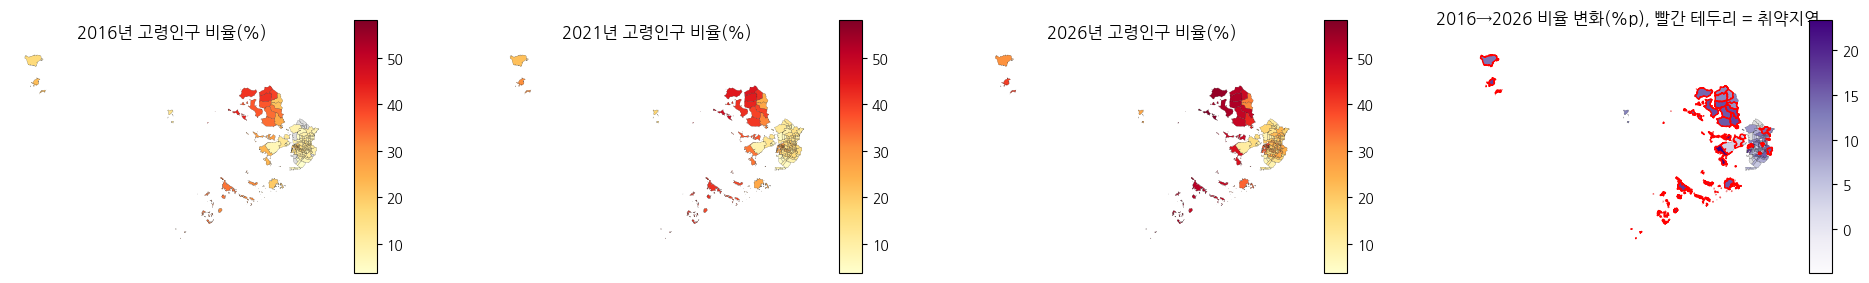

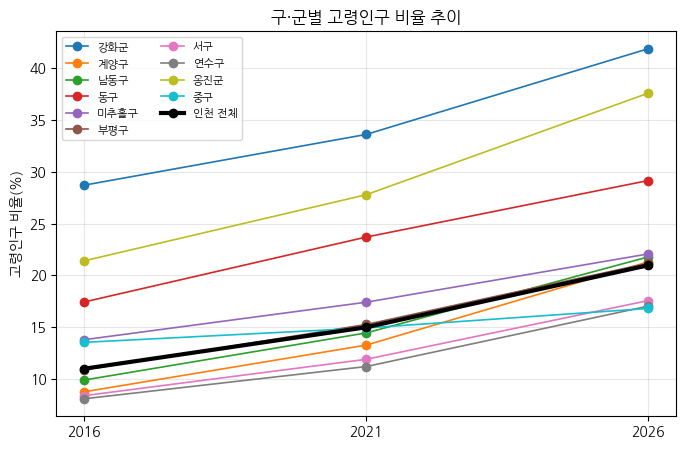

In [ ]:
# [셀 E2] 지도: 2016·2021·2026 고령 비율(같은 색 기준) + 10년 변화(취약지역 테두리) + 구별 추이 그래프 (한글)
!apt-get -qq install -y fonts-nanum > /dev/null
FONT = "/usr/share/fonts/truetype/nanum/NanumGothic.ttf"
import matplotlib.pyplot as plt, matplotlib.font_manager as fm
fm.fontManager.addfont(FONT); plt.rcParams["font.family"] = fm.FontProperties(fname=FONT).get_name()
plt.rcParams["axes.unicode_minus"] = False
bnd = gpd.read_file("dong_boundary.gpkg").to_crs(5179).astype({"adm_cd": str})
m = bnd[["adm_cd", "geometry"]].merge(dm, on="adm_cd")
vmin, vmax = m[["eld_ratio_2016", "eld_ratio_2026"]].min().min(), m[["eld_ratio_2016", "eld_ratio_2026"]].max().max()
fig, ax = plt.subplots(1, 4, figsize=(24, 6))
for a, y in zip(ax, [2016, 2021, 2026]):
    m.plot(f"eld_ratio_{y}", ax=a, cmap="YlOrRd", vmin=vmin, vmax=vmax, legend=True, edgecolor="k", linewidth=0.1,
           missing_kwds={"color": "#dddddd"}); a.set_title(f"{y}년 고령인구 비율(%)"); a.axis("off")
m.plot("d_ratio_16_26", ax=ax[3], cmap="Purples", legend=True, edgecolor="k", linewidth=0.1, missing_kwds={"color": "#dddddd"})
m[m["vuln"] != "비취약"].boundary.plot(ax=ax[3], color="red", linewidth=1)
ax[3].set_title("2016→2026 비율 변화(%p), 빨간 테두리 = 취약지역"); ax[3].axis("off")
plt.show()
fig, a = plt.subplots(figsize=(8, 5))
for gu, r in trend[[2016, 2021, 2026]].iterrows():
    a.plot([2016, 2021, 2026], r.values, marker="o", lw=3 if gu == "인천 전체" else 1.2, color="k" if gu == "인천 전체" else None, label=gu)
a.set_xticks([2016, 2021, 2026]); a.set_ylabel("고령인구 비율(%)"); a.set_title("구·군별 고령인구 비율 추이")
a.legend(fontsize=8, ncol=2); a.grid(alpha=0.3)
plt.show()

In [ ]:
# [셀 E3] 취약지역은 고령화도 빨랐나? + 취약지역 31개의 고령화 속도 순위 → 저장
from scipy.stats import mannwhitneyu
r = dm["d_ratio_16_26"].rank(ascending=False, method="min")
dm["aging_rank"], dm["aging_fast"] = r.astype("Int64"), (r <= round(len(dm) * 0.2)).astype(int)   # 비율 상승 순위, 상위 20%면 1
grp = dm["vuln"].replace({"확정": "취약", "경계": "취약"})
print(dm.groupby(grp)[["eld_ratio_2016", "eld_ratio_2026", "d_ratio_16_26", "eld_gr_16_26"]].median().round(1).to_string())
for c in ["d_ratio_16_26", "eld_gr_16_26"]:
    a, b = dm.loc[grp == "취약", c].dropna(), dm.loc[grp == "비취약", c].dropna()
    print(f"{c}: 취약 중앙값 {a.median():.1f} vs 비취약 {b.median():.1f} / Mann-Whitney p = {mannwhitneyu(a, b).pvalue:.3f}")
cols = ["adm_nm", "vuln", "pattern", "policy", "eld_ratio_2016", "eld_ratio_2026", "d_ratio_16_26", "eld_gr_16_26", "aging_rank"]
print("\n[취약지역 31개, 비율 상승 큰 순] aging_rank = 156개 동 중 순위")
print(dm.loc[grp == "취약", cols].sort_values("d_ratio_16_26", ascending=False).to_string(index=False))
dm.to_csv("dong_master.csv", index=False, encoding="utf-8-sig")
files.download("dong_master.csv")

      eld_ratio_2016  eld_ratio_2026  d_ratio_16_26  eld_gr_16_26
vuln                                                             
비취약             10.9            22.1           11.3          82.8
취약              22.3            40.0           15.6          50.1
d_ratio_16_26: 취약 중앙값 15.6 vs 비취약 11.3 / Mann-Whitney p = 0.000
eld_gr_16_26: 취약 중앙값 50.1 vs 비취약 82.8 / Mann-Whitney p = 0.000

[취약지역 31개, 비율 상승 큰 순] aging_rank = 156개 동 중 순위
 adm_nm vuln pattern              policy  eld_ratio_2016  eld_ratio_2026  d_ratio_16_26  eld_gr_16_26  aging_rank
    용유동   확정     산발형              이동형 의료           23.32           46.66          23.34          41.3           1
    북도면   확정     밀집형              이동형 의료           27.45           49.30          21.85          65.6           3
   화수2동   확정     산발형               병원 동행           18.63           38.07          19.44          49.4           6
    덕적면   확정     밀집형              이동형 의료           33.56           51.69          18.13          38.7    

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# [셀 G1-0] 읍면동 연령별 인구 파일 올리기 + 파일별 줄 수 확인
for f in files.upload(): print("올림:", f)
for f in [f for f in os.listdir() if "연령별인구" in f]: print(f, len(pd.read_excel(f, header=None, usecols=[0])), "줄")

Saving 202606_202606_연령별인구현황_월간.xlsx to 202606_202606_연령별인구현황_월간.xlsx
올림: 202606_202606_연령별인구현황_월간.xlsx
2026년 6월 인천광역시_연령별인구현황_월간.xlsx 15 줄


/usr/local/lib/python3.13/dist-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")
/usr/local/lib/python3.13/dist-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


202606_202606_연령별인구현황_월간.xlsx 3922 줄


In [ ]:
# [셀 G1] ⑦ 2031 고령인구: 동별 2026년 60세 이상(5세 묶음) × 5년 생존율(인천 간이생명표 2023) → 인천 추계 증가율에 맞춤
K26, K31 = 596, 758                                   # 장래인구추계 인천 65세 이상(천 명), 중위 추계
AGE = max([f for f in os.listdir() if "연령별인구" in f], key=lambda f: len(pd.read_excel(f, header=None, usecols=[0])))   # 줄이 가장 많은 파일 = 읍면동 파일
LT = find("생명표")
print("쓰는 파일:", AGE, "/", LT)
raw = pd.read_excel(AGE, header=None, dtype=str)
hr = raw.index[raw.iloc[:, 0].astype(str).str.strip() == "행정기관코드"][0]
col = {}
for j, v in enumerate(raw.iloc[hr].astype(str).str.strip()):            # 첫 블록(계)의 1세별 열만
    mt = re.fullmatch(r"(\d+)세( 이상)?", v)
    if mt and int(mt.group(1)) not in col: col[int(mt.group(1))] = j
A = raw.iloc[hr + 1:, [0, 1] + list(col.values())].copy(); A.columns = ["code", "name"] + list(col)
A = A.dropna(subset=["code"]); A["code"] = A["code"].str.strip()
A = A[A["code"].str.startswith("28")]                                    # 전국 파일이면 인천(28)만 남김
A[list(col)] = A[list(col)].apply(lambda s: pd.to_numeric(s.str.replace(",", ""), errors="coerce")).fillna(0)
gr = A[A["code"].str.endswith("00000") & (A["code"].str[2:5] != "000")]
GU_M = dict(zip(gr["code"].str[:5], gr["name"].str.split().str[-1]))   # 원자료 구 코드 → 구 이름
A = A[~A["code"].str.endswith("00000")].copy()
assert len(A) > 0, "이 파일은 구 단위야. 읍면동까지 나오게 다시 받아 줘"
A["gu"], A["nm"] = A["code"].str[:5].map(GU_M), A["name"].str.split().str[-1]
GRP = {60: range(60, 65), 65: range(65, 70), 70: range(70, 75), 75: range(75, 80), 80: range(80, 85), 85: range(85, 101)}
for g, r in GRP.items(): A[f"p{g}"] = A[[a for a in r if a in A]].sum(axis=1)
A["eld65_file"] = A[[a for a in range(65, 101) if a in A]].sum(axis=1)
for enc in ["utf-8-sig", "cp949"]:
    try: lt = pd.read_csv(LT, encoding=enc, header=None, dtype=str); break
    except UnicodeDecodeError: pass
lt = lt[lt[1].str.match(r"\s*\d")]
L = {int(re.match(r"\s*(\d+)", a).group(1)): float(str(v).replace(",", "")) for a, v in zip(lt[1], lt[2])}
T = lambda x: sum(v for a, v in L.items() if a >= x)                      # x세 이상 정지인구 합
SURV = {60: L[65] / L[60], 65: L[70] / L[65], 70: L[75] / L[70], 75: L[80] / L[75], 80: L[85] / L[80], 85: T(90) / T(85)}
print("5년 생존율:", {f"{g}{'+' if g == 85 else f'-{g + 4}'}세": round(s, 4) for g, s in SURV.items()})
A["eld_2031_raw"] = sum(A[f"p{g}"] * s for g, s in SURV.items())
FIX2 = {"중구|운서1동": "운서동", "중구|운서2동": "운서동", "서구|아라1동": "아라동", "서구|아라2동": "아라동",   # 분동된 동 → 원래 동
        "강화군|서도면볼음출장소": "서도면", "옹진군|북도면장봉출장소": "북도면",                       # 출장소 → 본 면
        "옹진군|대청면소청출장소": "대청면", "옹진군|자월면이작출장소": "자월면"}
KEY = {(g, norm(n)): cd for cd, g, n in zip(dm["adm_cd"], dm["gu"], dm["adm_nm"])}
A["adm_cd"] = [KEY.get((g, norm(FIX2.get(f"{g}|{n}", n)))) for g, n in zip(A["gu"], A["nm"])]
print("원자료 읍면동:", len(A), "/ 짝 못 찾은 원자료 동:", (A["gu"] + "|" + A["nm"])[A["adm_cd"].isna()].tolist())
F = A.dropna(subset=["adm_cd"]).groupby("adm_cd")[[f"p{g}" for g in GRP] + ["eld65_file", "eld_2031_raw"]].sum()
print("원자료가 없는 dong_master 동:", dm.loc[~dm["adm_cd"].isin(F.index), "adm_nm"].tolist())
d = (F["eld65_file"] - dm.set_index("adm_cd")["eld_65"]).abs()
print(f"원자료 65세+ vs eld_65: 다른 동 {int((d > 0).sum())}개, 최대 차이 {d.max():.0f}명 (0이면 같은 자료)")
F["eld_65"] = dm.set_index("adm_cd")["eld_65"].reindex(F.index)
target = F["eld_65"].sum() * K31 / K26                                   # 짝 찾은 동의 2026 합 × 추계 증가율
F["eld_2031"] = F["eld_65"] * F["eld_2031_raw"] / F["eld65_file"]          # 원자료 안에서 구한 동별 증가 비율을 eld_65에 곱함
k = target / F["eld_2031"].sum(); F["eld_2031"] = (F["eld_2031"] * k).round()
print(f"코호트만 증가율 {F['eld_2031_raw'].sum() / F['eld65_file'].sum() - 1:+.1%} → 추계 증가율 {K31 / K26 - 1:+.1%}에 맞춤"
      f" / 조정 배수 {k:.3f} / 2031 합계 {F['eld_2031'].sum():,.0f}")
dm = dm.drop(columns=["eld_2031_raw", "eld_2031"], errors="ignore").merge(F[["eld_2031_raw", "eld_2031"]].round(), left_on="adm_cd", right_index=True, how="left")
miss31 = dm["eld_2031"].isna()                                           # 원자료 짝이 없는 동은 인천 평균 증가율로 임시 채움
dm.loc[miss31, "eld_2031"] = (dm.loc[miss31, "eld_65"] * K31 / K26).round()
print("인천 평균 증가율로 임시로 채운 동:", dm.loc[miss31, "adm_nm"].tolist())
F.reset_index().to_csv("dong_future.csv", index=False, encoding="utf-8-sig")

/usr/local/lib/python3.13/dist-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")
/usr/local/lib/python3.13/dist-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


쓰는 파일: 202606_202606_연령별인구현황_월간.xlsx / 시도별_간이생명표_5세별__20261012181211.csv


/usr/local/lib/python3.13/dist-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


5년 생존율: {'60-64세': 0.9676, '65-69세': 0.9458, '70-74세': 0.9068, '75-79세': 0.8236, '80-84세': 0.6873, '85+세': 0.4064}
원자료 읍면동: 162 / 짝 못 찾은 원자료 동: []
원자료가 없는 dong_master 동: []
원자료 65세+ vs eld_65: 다른 동 153개, 최대 차이 61명 (0이면 같은 자료)
코호트만 증가율 +23.5% → 추계 증가율 +27.2%에 맞춤 / 조정 배수 1.029 / 2031 합계 761,549
인천 평균 증가율로 임시로 채운 동: []


In [ ]:
# [셀 G2] 과거 추이와 비교: 2021→2026 증가율이 2031까지 그대로 이어진다고 본 값(추세 연장) vs 코호트 값
from scipy.stats import spearmanr
new_dong = dm[["eld_2016", "eld_2021"]].isna().any(axis=1)                   # 2016 이후 신설·분동 동은 추세가 튀어서 뺌
dm["eld_2031_trend"] = (dm["eld_65"] ** 2 / dm["eld_2021"]).round().where(~new_dong)   # 2026 × (2026 ÷ 2021)
print("추세 비교에서 뺀 신설 동:", dm.loc[new_dong, "adm_nm"].tolist())
c, t = dm["eld_2031"] / dm["eld_65"] * 100 - 100, dm["eld_2031_trend"] / dm["eld_65"] * 100 - 100
print(f"인천 합계(신설 동 뺀 {(~new_dong).sum()}개): 코호트 {dm.loc[~new_dong, 'eld_2031'].sum():,.0f} / 추세 연장 {dm['eld_2031_trend'].sum():,.0f}")
print(f"동별 증가율 순위상관(코호트 vs 추세): {spearmanr(c, t, nan_policy='omit')[0]:.2f}")
v = dm.assign(코호트=c.round(1), 추세=t.round(1), 차이=(t - c).round(1))[["adm_nm", "gu", "vuln", "eld_65", "eld_2031", "eld_2031_trend", "코호트", "추세", "차이"]]
print("\n[추세가 코호트보다 훨씬 큰 동: 고령자 유입이 많았던 곳]\n" + v.nlargest(8, "차이").to_string(index=False))
print("\n[추세가 코호트보다 훨씬 작은 동: 고령자 유출이 많았던 곳]\n" + v.nsmallest(8, "차이").to_string(index=False))

추세 비교에서 뺀 신설 동: ['송도4동', '송도5동', '서창2동', '청라3동', '검단동', '불로대곡동', '당하동', '마전동', '원당동', '아라동']
인천 합계(신설 동 뺀 146개): 코호트 698,495 / 추세 연장 777,852
동별 증가율 순위상관(코호트 vs 추세): 0.80

[추세가 코호트보다 훨씬 큰 동: 고령자 유입이 많았던 곳]
adm_nm  gu vuln  eld_65  eld_2031  eld_2031_trend  코호트    추세    차이
  송림1동  동구  비취약    1207    1438.0          3209.0 19.1 165.9 146.7
  청천1동 부평구  비취약    3093    4194.0          8156.0 35.6 163.7 128.1
  가정2동  서구  비취약    1944    2932.0          4592.0 50.8 136.2  85.4
  영종1동  중구  비취약    3565    4597.0          6742.0 28.9  89.1  60.2
  영종2동  중구  비취약    2411    3180.0          4559.0 31.9  89.1  57.2
   영종동  중구   확정    4958    6702.0          9379.0 35.2  89.2  54.0
  십정1동 부평구  비취약    4341    5465.0          7448.0 25.9  71.6  45.7
  가정1동  서구  비취약    5765    7833.0         10084.0 35.9  74.9  39.0

[추세가 코호트보다 훨씬 작은 동: 고령자 유출이 많았던 곳]
adm_nm   gu vuln  eld_65  eld_2031  eld_2031_trend  코호트    추세    차이
  송림2동   동구  비취약     538     539.0           291.0  0.2 -45.9 -46.1
송림3·5동   동구  비취약    

In [ ]:
# 건물 버전 지우고 격자 버전 올리기
os.remove("demand_points.gpkg")
for f in files.upload():
    if f.startswith("demand_points") and f != "demand_points.gpkg": os.rename(f, "demand_points.gpkg")
print("수요점 개수:", len(gpd.read_file("demand_points.gpkg")), "(25,527이어야 해)")

Saving demand_points.gpkg to demand_points.gpkg
수요점 개수: 25527 (25,527이어야 해)


In [ ]:
# [셀 F2] ⑦ 2031 2SFCA: 공급은 그대로, 격자 고령인구만 동별 (2031 ÷ 2026) 비율로 늘려서 600m·1km 다시 계산
from scipy.spatial import cKDTree
NEED = {"demand_points": ".gpkg", "facilities": ".gpkg"}
miss = [b + e for b, e in NEED.items() if not os.path.exists(b + e)]
if miss:
    print("올릴 파일:", miss)
    for f in files.upload():
        for b, e in NEED.items():
            if f.startswith(b) and f != b + e: os.rename(f, b + e)
pts = gpd.read_file("demand_points.gpkg").to_crs(5179); pts["adm_cd"] = pts["adm_cd"].astype(str)
fac = gpd.read_file("facilities.gpkg").to_crs(5179)
fac = fac[fac.geometry.notna() & (fac["S"] > 0) & (fac["name"] != "인천국제공항의원")].reset_index(drop=True)   # ②와 같은 공급
k = dm.set_index("adm_cd")["eld_2031"] / pts.groupby("adm_cd")["eld_2026"].sum()
pts["eld_2031"] = (pts["eld_2026"] * pts["adm_cd"].map(k)).fillna(0)          # 동 안 배분 비율은 2026과 같음
print(f"고령인구 합 2026 {pts['eld_2026'].sum():,.0f} → 2031 {pts['eld_2031'].sum():,.0f} (dong eld_2031 합 {dm['eld_2031'].sum():,.0f})")
tree_p, tree_f = cKDTree(np.c_[pts.geometry.x, pts.geometry.y]), cKDTree(np.c_[fac.geometry.x, fac.geometry.y])
S = fac["S"].to_numpy(float)
def two_sfca(P, d0):                                                            # ② 셀 A2와 같은 함수
    nb = tree_f.query_ball_tree(tree_p, r=d0)
    fi = np.repeat(np.arange(len(nb)), [len(n) for n in nb])
    pj = np.fromiter((j for n in nb for j in n), dtype=int, count=len(fi))
    demand = np.bincount(fi, weights=P[pj], minlength=len(S))
    R = np.divide(S * 1000, demand, out=np.zeros(len(S)), where=demand > 0)
    return np.bincount(pj, weights=R[fi], minlength=len(P))
def to_dong(A, w):                                                              # ② 셀 A4와 같은 가중평균
    return (A * w).groupby(pts["adm_cd"]).sum() / w.groupby(pts["adm_cd"]).sum()
for d0 in (600, 1000):
    chk = to_dong(two_sfca(pts["eld_2026"].to_numpy(float), d0), pts["eld_2026"])
    diff = (dm.set_index("adm_cd")[f"acc_{d0}"] - chk).abs().max()
    print(f"[{d0}m] 2026 재계산과 기존 acc_{d0}의 최대 차이: {diff:.4f}  (0에 가까워야 같은 설정)")
    dm[f"acc_{d0}_2031"] = dm["adm_cd"].map(to_dong(two_sfca(pts["eld_2031"].to_numpy(float), d0), pts["eld_2031"])).round(4)
dm["eld_gr_26_31"] = ((dm["eld_2031"] / dm["eld_65"] - 1) * 100).round(1)                     # 2026→2031 고령인구 증가율(%)
dm["acc_600_chg"] = ((dm["acc_600_2031"] / dm["acc_600"].replace(0, np.nan) - 1) * 100).round(1)  # 600m 지수 변화율(%)
print(dm[["acc_600", "acc_600_2031", "acc_1000", "acc_1000_2031", "eld_gr_26_31", "acc_600_chg"]].describe().round(2).to_string())

고령인구 합 2026 598,793 → 2031 761,549 (dong eld_2031 합 761,549)
[600m] 2026 재계산과 기존 acc_600의 최대 차이: 0.0000  (0에 가까워야 같은 설정)
[1000m] 2026 재계산과 기존 acc_1000의 최대 차이: 0.0000  (0에 가까워야 같은 설정)
       acc_600  acc_600_2031  acc_1000  acc_1000_2031  eld_gr_26_31  acc_600_chg
count   156.00        156.00    156.00         156.00        156.00       139.00
mean      1.84          1.43      1.84           1.43         24.80       -20.60
std       1.66          1.26      1.49           1.10         11.76         5.95
min       0.00          0.00      0.00           0.00          0.20       -35.00
25%       0.78          0.63      1.02           0.81         16.82       -24.40
50%       1.42          1.17      1.51           1.23         25.50       -21.00
75%       2.51          1.93      2.43           1.95         31.68       -17.00
max       9.53          7.52      7.92           5.43         57.60        -9.30


In [ ]:
# [점검] F2 재계산이 ②와 다른 이유 찾기: 지금 코랩에 있는 수요점·기관 파일이 ② 때 파일과 같은지
for f in ["demand_points.gpkg", "facilities.gpkg"]:
    print(f, f"{os.path.getsize(f) / 1e6:.1f}MB")
print("수요점 개수:", len(pts), "(② 때 25,527개) / 열:", pts.columns.tolist())
print(f"수요점 eld_2026 합 {pts['eld_2026'].sum():,.0f} / dong_master eld_65 합 {dm['eld_65'].sum():,.0f}")
print("수요점이 하나도 없는 동:", dm.loc[~dm["adm_cd"].isin(pts["adm_cd"]), "adm_nm"].tolist())
print("의료기관(S>0, 공항의원 뺌):", len(fac), "/ S 합:", fac["S"].sum())
chk = dm[["adm_cd", "adm_nm", "acc_600"]].copy()
chk["재계산"] = chk["adm_cd"].map(to_dong(two_sfca(pts["eld_2026"].to_numpy(float), 600), pts["eld_2026"])).round(4)
chk["차이"] = (chk["재계산"] - chk["acc_600"]).round(4)
print("\n600m 차이가 0.01 넘는 동:", int((chk["차이"].abs() > 0.01).sum()), "개")
print(chk.reindex(chk["차이"].abs().sort_values(ascending=False).index).head(12).to_string(index=False))

demand_points.gpkg 14.5MB
facilities.gpkg 0.2MB
수요점 개수: 116550 (② 때 25,527개) / 열: ['bld_id', 'adm_cd', 'hh', 'eld_2026', 'in_transit', 'in_rail', 'weight_basis', 'source_fid', 'source_bld_id', 'geometry', 'eld_2031']
수요점 eld_2026 합 591,167 / dong_master eld_65 합 598,793
수요점이 하나도 없는 동: ['송도4동', '송도5동']
의료기관(S>0, 공항의원 뺌): 696 / S 합: 1213

600m 차이가 0.01 넘는 동: 119 개
  adm_cd adm_nm  acc_600    재계산      차이
23010691   영종2동   3.4376 0.0000 -3.4376
23010681   영종1동   2.7243 0.0000 -2.7243
23040650   송도3동   3.1012 0.4784 -2.6228
23040640   송도1동   7.0722 9.3150  2.2428
23090570   용현3동   1.3358 3.2223  1.8865
23080740   청라1동   3.3168 4.7502  1.4334
23040660   송도2동   7.3469 8.5079  1.1610
23040570   동춘1동   2.6855 3.6526  0.9671
23040590   동춘3동   3.5327 2.6471 -0.8856
23040580   동춘2동   2.6447 1.8133 -0.8314
23070620   계산4동   3.4639 2.6715 -0.7924
23080780   청라2동   2.3432 1.6356 -0.7076


In [ ]:
# [셀 F3] ⑦ 2031 판정: (가) 2026 하위 20% 기준값을 그대로 적용  (나) 2031 값 안에서 다시 하위 20%
n20 = round(len(dm) * 0.2)
cut = {c: dm.loc[dm[c].rank(method="min") <= n20, c].max() for c in ["acc_600", "acc_1000"]}
print("2026 하위 20% 기준값:", {c: round(v, 4) for c, v in cut.items()})
b6, b10 = dm["acc_600_2031"] <= cut["acc_600"], dm["acc_1000_2031"] <= cut["acc_1000"]
dm["vuln_2031"] = np.select([b6 & b10, b6], ["확정", "경계"], "비취약")
r6, r10 = dm["acc_600_2031"].rank(method="min") <= n20, dm["acc_1000_2031"].rank(method="min") <= n20
dm["vuln_2031_rel"] = np.select([r6 & r10, r6], ["확정", "경계"], "비취약")
print("2026 기준값으로 2026을 다시 판정해도 같은지:", ((dm["acc_600"] <= cut["acc_600"]) == (dm["vuln"] != "비취약")).all())
for c, t in [("vuln_2031", "(가) 2026 기준값 고정"), ("vuln_2031_rel", "(나) 2031 안에서 하위 20%")]:
    print(f"\n[{t}] 행 = 2026, 열 = 2031\n" + pd.crosstab(dm["vuln"], dm[c], margins=True, margins_name="합계").to_string())
cols = ["adm_nm", "gu", "vuln", "vuln_2031", "vuln_2031_rel", "acc_600", "acc_600_2031", "acc_600_chg", "eld_65", "eld_2031", "eld_gr_26_31"]
cols += [c for c in ["d_ratio_16_26", "aging_fast"] if c in dm]
new = dm[(dm["vuln"] == "비취약") & ((dm["vuln_2031"] != "비취약") | (dm["vuln_2031_rel"] != "비취약"))]
print(f"\n[2031에 새로 취약해지는 동] {len(new)}개 (가 또는 나 기준)")
print(new.sort_values("acc_600_2031")[cols].to_string(index=False))
out = dm[(dm["vuln"] != "비취약") & (dm["vuln_2031_rel"] == "비취약")]
print(f"\n[(나) 기준에서 취약지역을 벗어나는 동] {len(out)}개:", out["adm_nm"].tolist())
print("\n[2026→2031 고령인구 증가율 상위 10개 동]")
print(dm.nlargest(10, "eld_gr_26_31")[cols].to_string(index=False))

2026 하위 20% 기준값: {'acc_600': 0.6597, 'acc_1000': 0.7409}
2026 기준값으로 2026을 다시 판정해도 같은지: True

[(가) 2026 기준값 고정] 행 = 2026, 열 = 2031
vuln_2031  경계  비취약  확정   합계
vuln                       
경계          1    0   2    3
비취약         7  115   3  125
확정          0    0  28   28
합계          8  115  33  156

[(나) 2031 안에서 하위 20%] 행 = 2026, 열 = 2031
vuln_2031_rel  경계  비취약  확정   합계
vuln                           
경계              1    2   0    3
비취약             2  123   0  125
확정              1    0  27   28
합계              4  125  27  156

[2031에 새로 취약해지는 동] 10개 (가 또는 나 기준)
adm_nm   gu vuln vuln_2031 vuln_2031_rel  acc_600  acc_600_2031  acc_600_chg  eld_65  eld_2031  eld_gr_26_31  d_ratio_16_26  aging_fast
  가정2동   서구  비취약        경계            경계   0.6641        0.4747        -28.5    1944    2932.0          50.8           3.05           0
  가정3동   서구  비취약        경계            경계   0.6621        0.4889        -26.2    1884    2662.0          41.3          14.11           0
  계양3동  계양구  비취약        

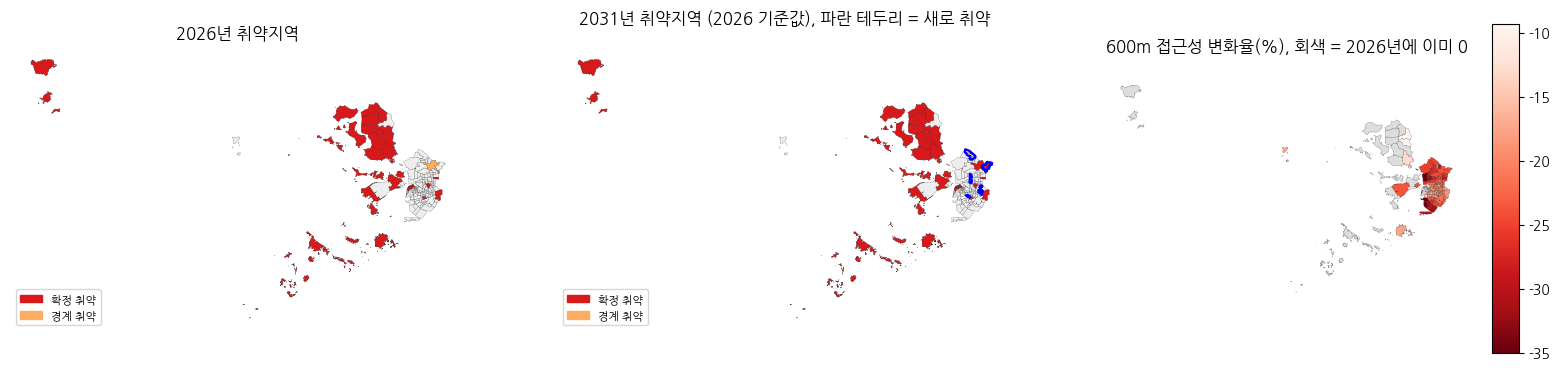

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# [셀 F4] 지도: 2026 판정 / 2031 판정(가) / 600m 지수 변화율 (+ 분양 단지 점) → 저장
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
m = bnd[["adm_cd", "geometry"]].merge(dm, on="adm_cd")
hs = gpd.read_file("housing_supply.gpkg").to_crs(5179) if os.path.exists("housing_supply.gpkg") else None
PAL = {"확정": ("확정 취약", "#d7191c"), "경계": ("경계 취약", "#fdae61")}
fig, ax = plt.subplots(1, 3, figsize=(20, 7))
for a, col, t in [(ax[0], "vuln", "2026년 취약지역"), (ax[1], "vuln_2031", "2031년 취약지역 (2026 기준값), 파란 테두리 = 새로 취약")]:
    m.plot(ax=a, color="#eeeeee", edgecolor="k", linewidth=0.1)
    for k, (lab, c) in PAL.items():
        if (m[col] == k).any(): m[m[col] == k].plot(ax=a, color=c, edgecolor="k", linewidth=0.1)
    a.legend(handles=[Patch(color=c, label=l) for l, c in PAL.values()], loc="lower left", fontsize=8); a.set_title(t); a.axis("off")
m[(m["vuln"] == "비취약") & (m["vuln_2031"] != "비취약")].boundary.plot(ax=ax[1], color="blue", linewidth=1.5)   # 새로 취약 = 파란 테두리
m.plot("acc_600_chg", ax=ax[2], cmap="Reds_r", legend=True, edgecolor="k", linewidth=0.1, missing_kwds={"color": "#dddddd"})
ax[2].set_title("600m 접근성 변화율(%), 회색 = 2026년에 이미 0"); ax[2].axis("off")
if hs is not None:
    for a in ax[1:]: hs.plot(ax=a, color="black", markersize=6, marker="^")
plt.show()
dm.to_csv("dong_master.csv", index=False, encoding="utf-8-sig")
files.download("dong_master.csv")